In [2]:
import qiskit
import qiskit_ibm_runtime
import pylatexenc

from qiskit import QuantumCircuit
from qiskit.quantum_info import SparsePauliOp
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager
from qiskit_ibm_runtime import EstimatorV2 as Estimator
from qiskit.circuit import Parameter
from qiskit.circuit.library import UGate
from qiskit.circuit.library import RXGate
from qiskit.quantum_info import SparsePauliOp
from qiskit_ibm_runtime.fake_provider import FakeAlmadenV2
from qiskit.primitives import StatevectorEstimator

import numpy as np
from numpy import pi

from itertools import product

from matplotlib import pyplot as plt
import matplotlib.cm as cm
import matplotlib.colors as mcolors

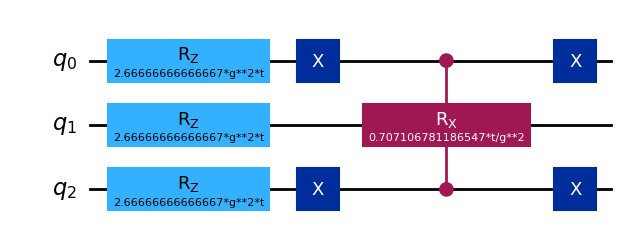

In [3]:
t = Parameter("t")
g = Parameter("g")

theta_E = (8 / 3) * g**2 * t
theta_B = 1 / (g**2 * np.sqrt(2)) * t

def one_step_new(n, N):
    qc = QuantumCircuit(n)
    
    for q in range(n):
        qc.rz(theta_E/N, q)

    for i in range(1, n - 1):       
        qc.x(i - 1)
        qc.x(i + 1)
        
        controlled_rx = RXGate(theta_B/N).control(2)  # 2 control qubits
        qc.append(controlled_rx, [i - 1, i + 1, i])

        qc.x(i - 1)
        qc.x(i + 1)
        
    return qc

def N_steps_compose_new(n, N):
    one_step_circuit = one_step_new(n, N)
    full_circuit = QuantumCircuit(n)
    for _ in range(N):
        full_circuit.compose(one_step_circuit, inplace=True)
    return full_circuit

n = 3
N = 1
circuit = N_steps_compose_new(n, N)
circuit.draw("mpl")

In [4]:
observables_labels = ["IZI", "ZZI", "IZZ", "ZIZ"]
observables = [SparsePauliOp(label) for label in observables_labels]

In [5]:
def plot_measurement_loop(n, N, t=1.0):
    circuit = N_steps_compose_new(n, N)
    pm = generate_preset_pass_manager(optimization_level=1)
    isa_circuit = pm.run(circuit)
    mapped_observables = [
        observable.apply_layout(isa_circuit.layout) for observable in observables
    ]

    estimator = StatevectorEstimator()
    job = estimator.run([(isa_circuit, mapped_observables, [1.0, t])])
    
    result = job.result()
 
    pub_result = job.result()[0]

    values = pub_result.data.evs
    labels = observables_labels
    return labels, values

In [6]:
def plot_measurement_loop_one_observable(n, N, o_index, t=1.0):
    circuit = N_steps_compose_new(n, N)
    pm = generate_preset_pass_manager(optimization_level=1)
    isa_circuit = pm.run(circuit)
    mapped_observables = [
        observables[o_index].apply_layout(isa_circuit.layout)
    ]

    estimator = StatevectorEstimator()
    job = estimator.run([(isa_circuit, mapped_observables, [1.0, t])])
    
    result = job.result()
 
    pub_result = job.result()[0]

    values = pub_result.data.evs
    labels = N
    return labels, values

In [7]:
plot_measurement_loop(3, 1)

(['IZI', 'ZZI', 'IZZ', 'ZIZ'],
 array([0.7602446, 0.7602446, 0.7602446, 1.       ]))

In [8]:
type(plot_measurement_loop(3, 1))

tuple

In [9]:
plot_measurement_loop_one_observable(3, 1, 0)

(1, array([0.7602446]))

In [10]:
exp_vals = []
Ns = np.arange(1, 21, 1)
for i in Ns:
    exp_val = plot_measurement_loop_one_observable(3, i, 0)[1][0] #IZI
    exp_vals.append(exp_val)
exp_vals

[0.76024459707563,
 0.8519225589527109,
 0.8642876905818244,
 0.8683448799955348,
 0.8701776153694529,
 0.8711614330918552,
 0.8717506892688327,
 0.8721315562369213,
 0.8723919600362129,
 0.8725778682495771,
 0.8727152279442423,
 0.872819592431114,
 0.872900747544852,
 0.8729651011936858,
 0.8730169923645472,
 0.8730594441700925,
 0.8730946153807403,
 0.8731240809583392,
 0.8731490118075632,
 0.8731702931061945]

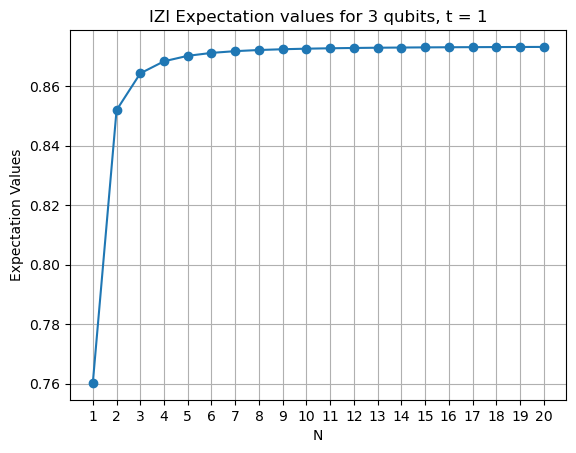

In [11]:
plt.plot(Ns, exp_vals, "-o")
plt.xticks(np.arange(1, 21, 1))
plt.xlabel("N")
plt.ylabel("Expectation Values")
plt.title("IZI Expectation values for 3 qubits, t = 1")
plt.grid(True)
plt.show()

In [78]:
def exp_val_one_observable(n, N, o, t):
    exp_vals = []
    Ns = np.arange(1, N+1, 1)
    for i in Ns:
        exp_val = plot_measurement_loop_one_observable(n, i, o, t)[1][0]
        exp_vals.append(exp_val)

    plt.plot(Ns, exp_vals, "-o")
    plt.xticks(np.arange(1, N+1, 1))
    plt.ticklabel_format(useOffset=False, style='plain', axis='y')
    plt.xlabel("N")
    plt.ylabel(f"{observables_labels[o]} Expectation Values for {n} qubits, t = {int(t)}")
    plt.title("")
    plt.grid(True)
    plt.show()

    # return statement can return the array of expectation values
    # return exp_vals

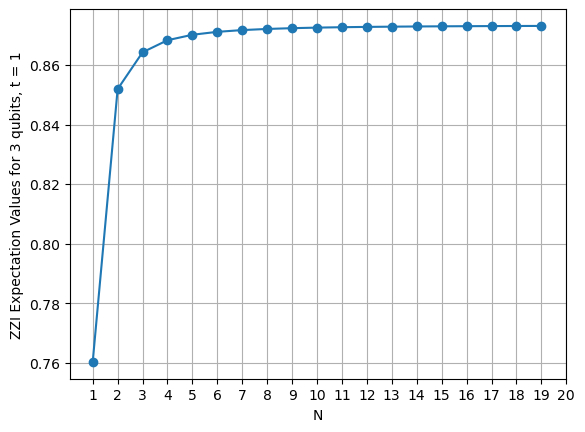

In [79]:
exp_val_one_observable(3, 20, 1, 1.0) #ZZI

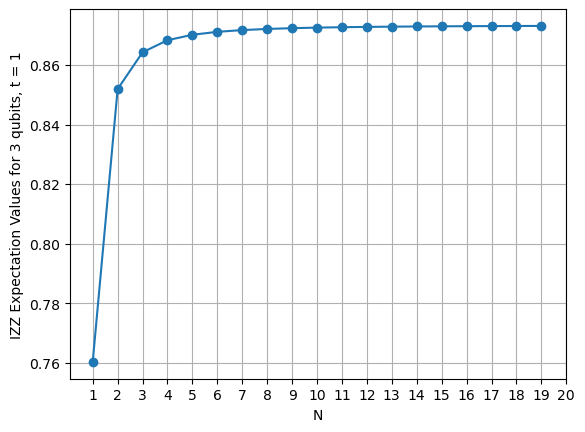

In [80]:
exp_val_one_observable(3, 20, 2, 1.0) #IZZ

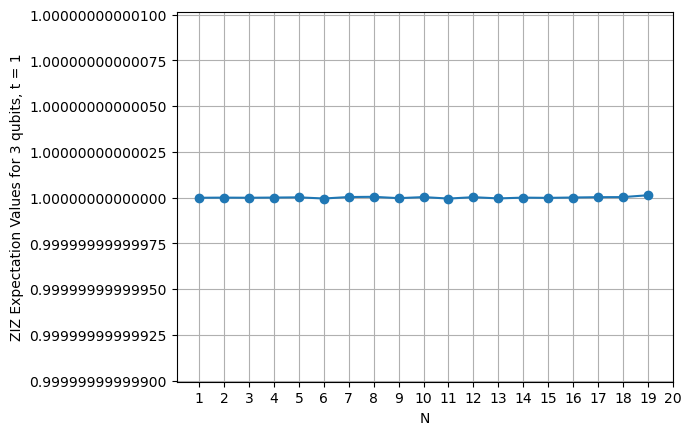

In [81]:
exp_val_one_observable(3, 20, 3, 1.0) #ZIZ

<h1>Time t=2</h1>

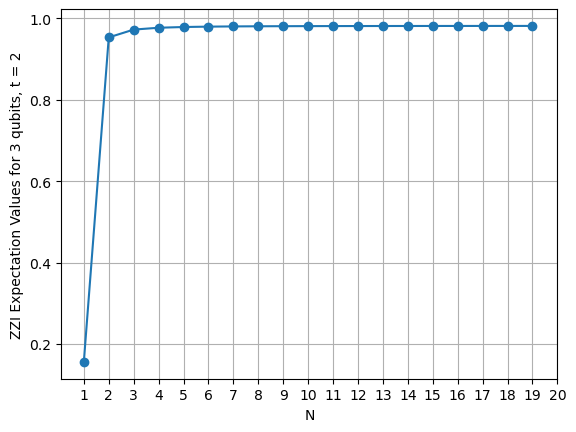

In [83]:
exp_val_one_observable(3, 20, 1, 2.0) #ZZI

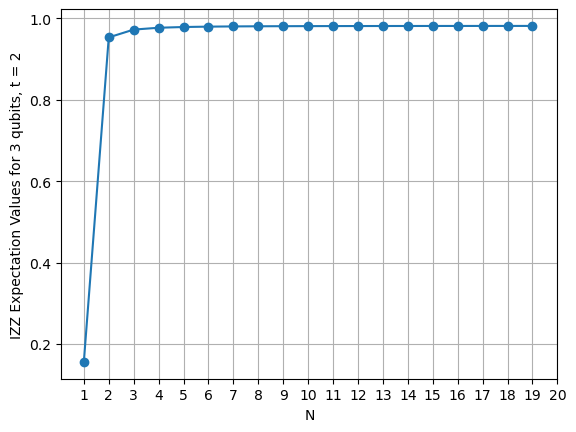

In [84]:
exp_val_one_observable(3, 20, 2, 2.0) #IZZ

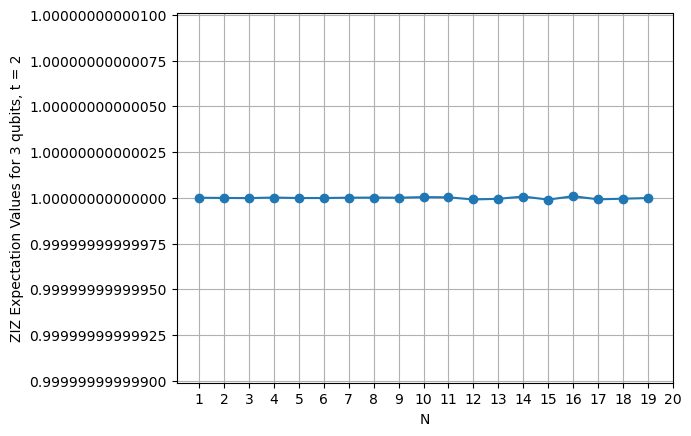

In [85]:
exp_val_one_observable(3, 20, 3, 2.0) #ZIZ

<h1>T = more</h1>

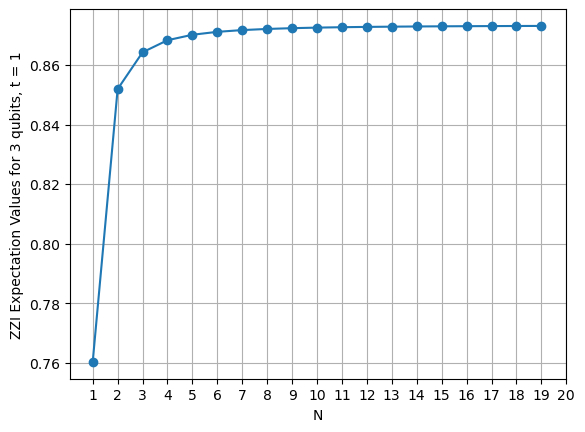

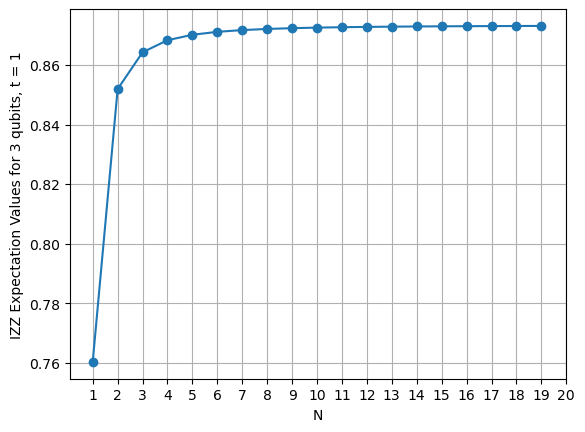

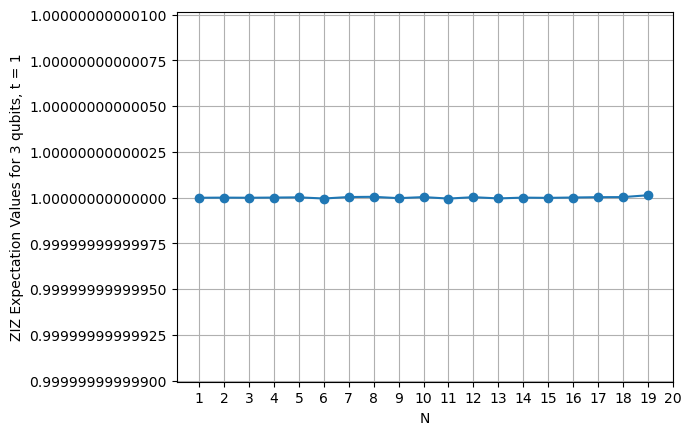

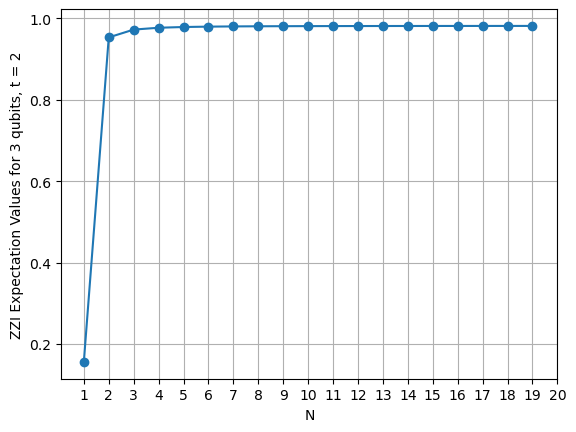

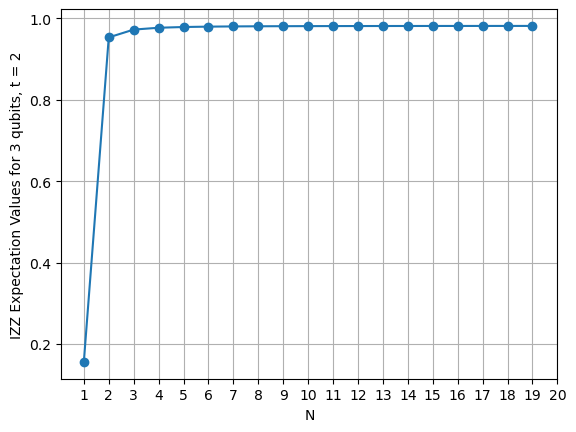

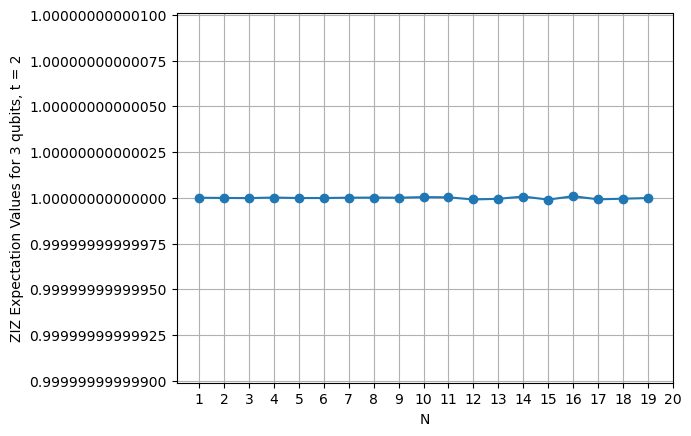

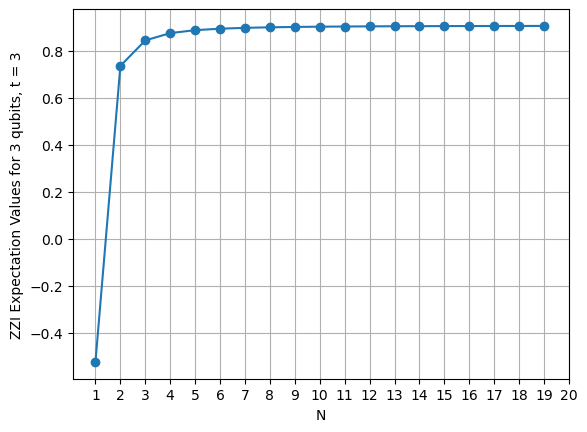

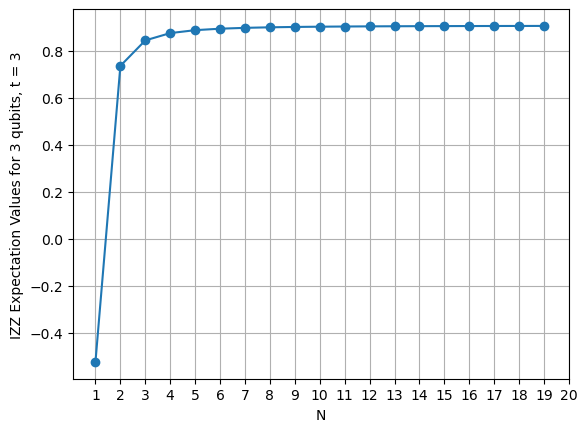

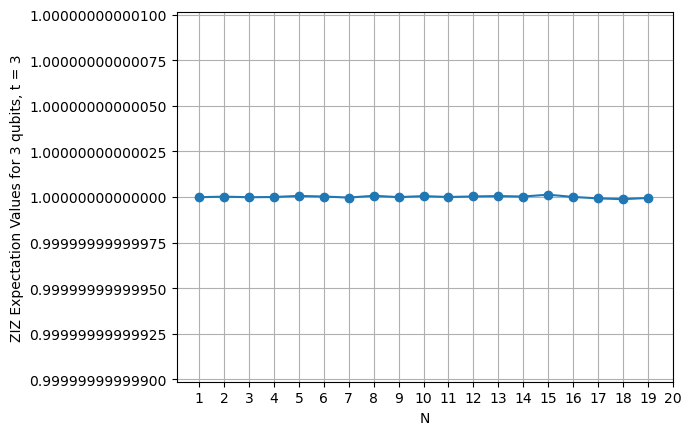

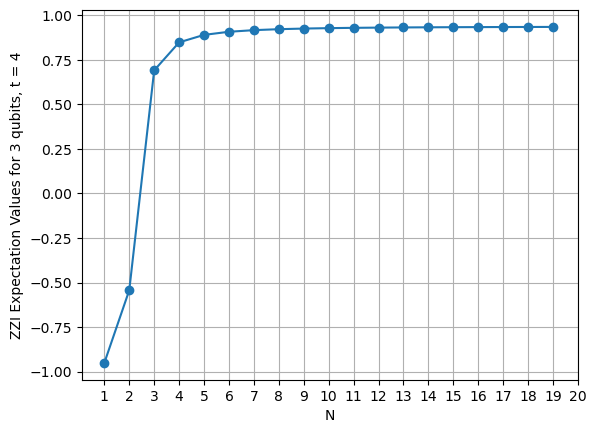

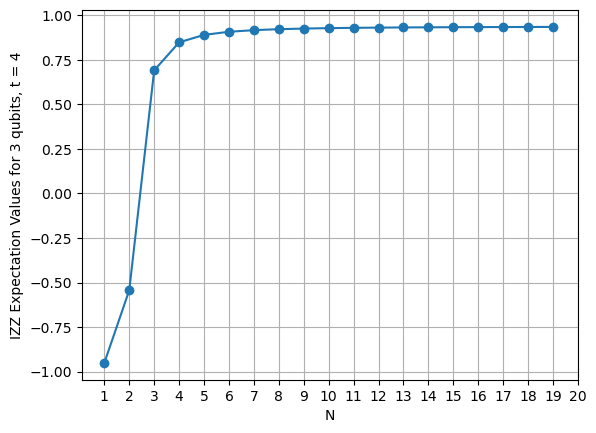

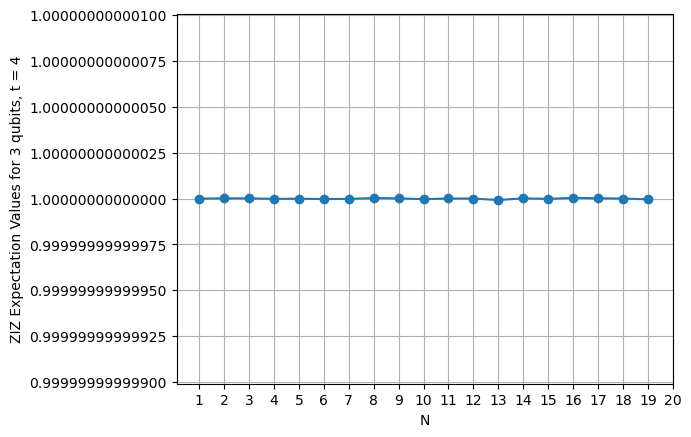

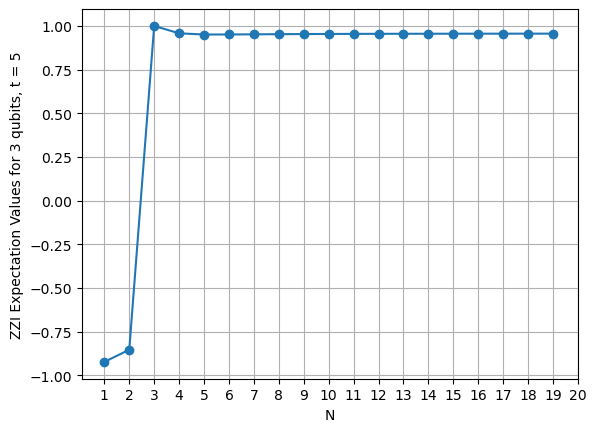

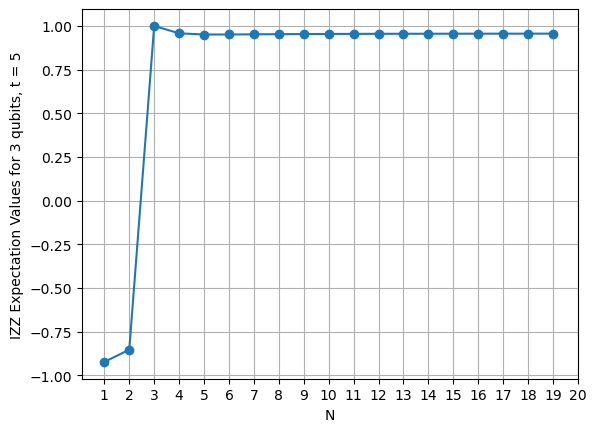

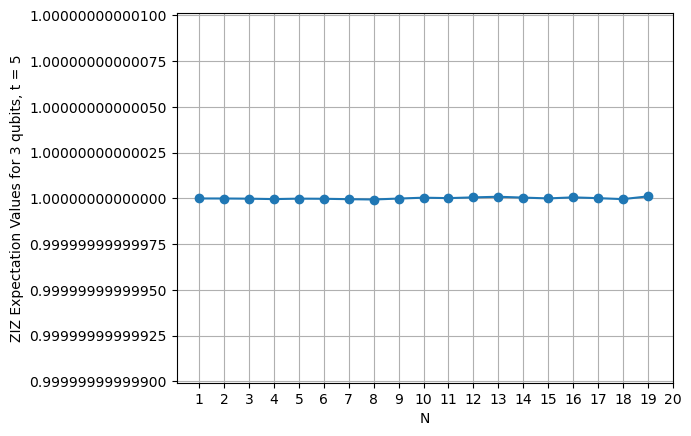

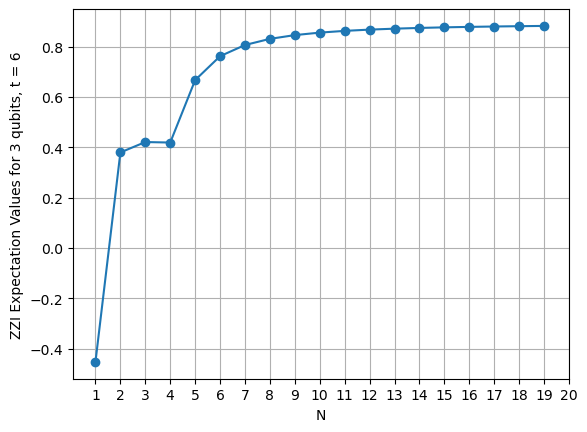

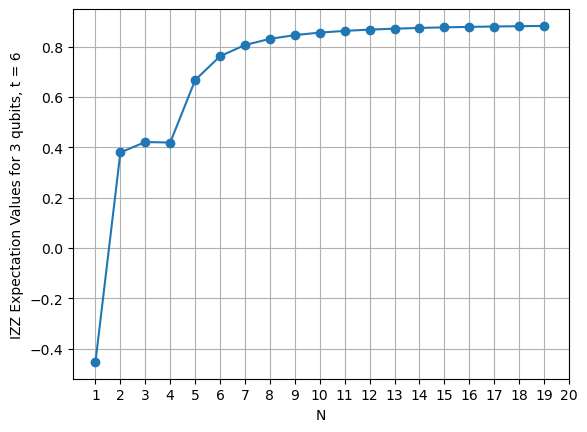

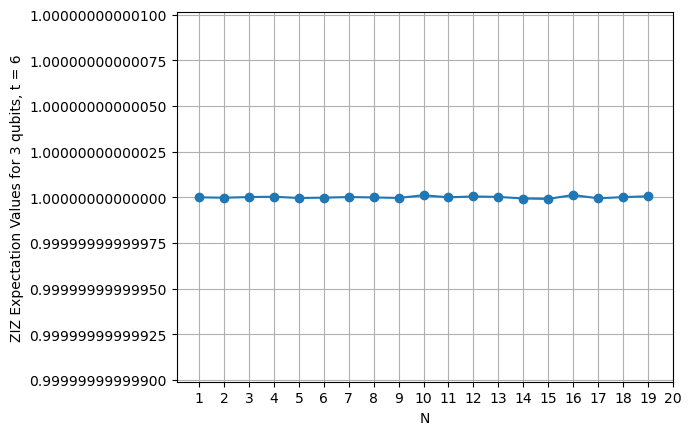

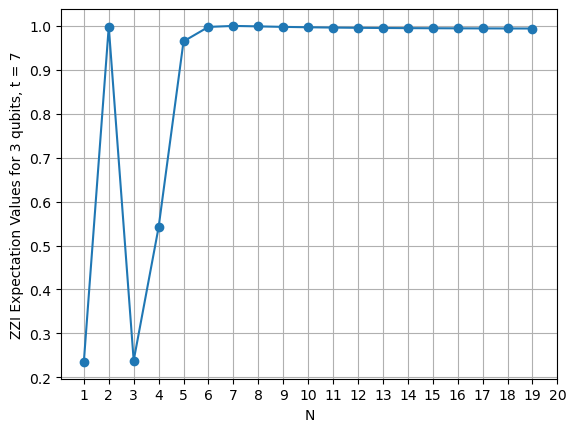

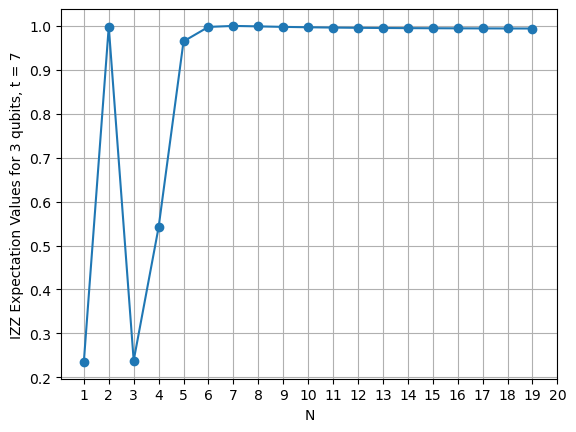

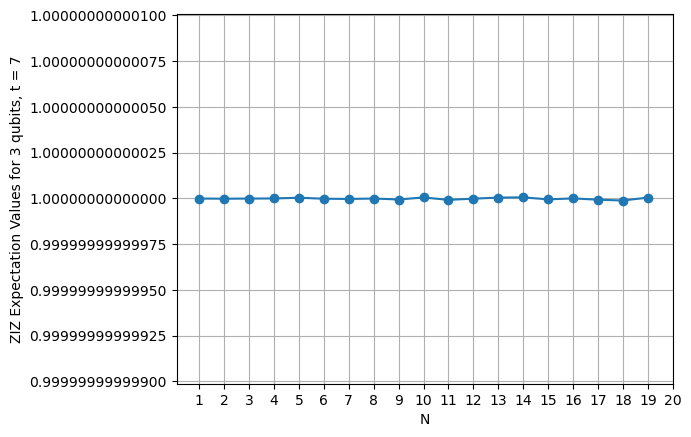

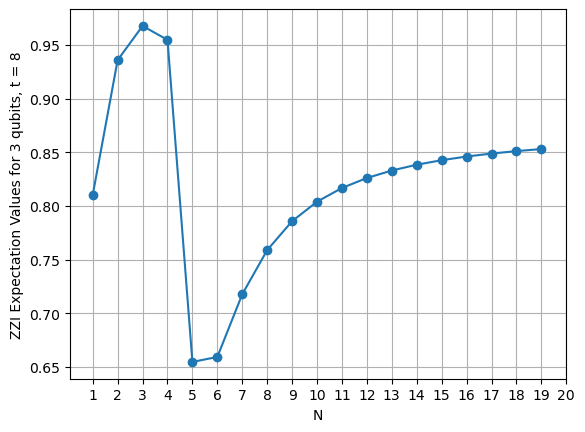

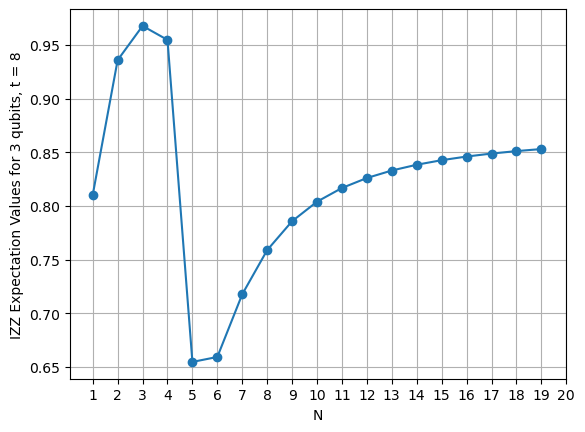

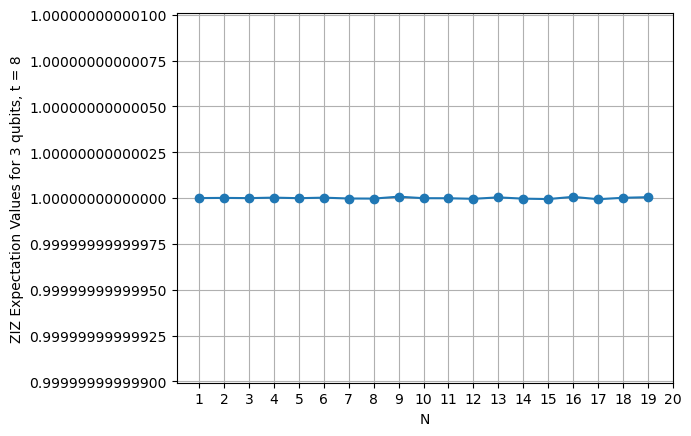

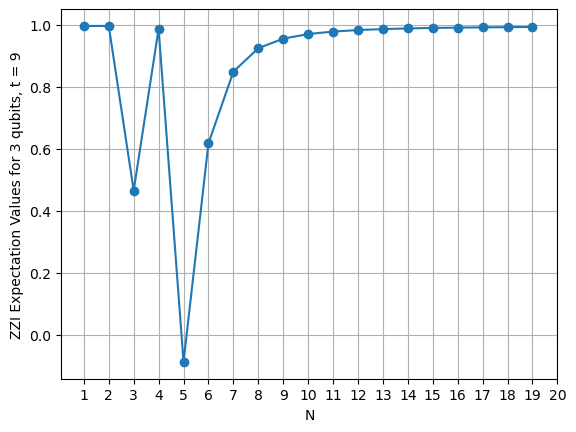

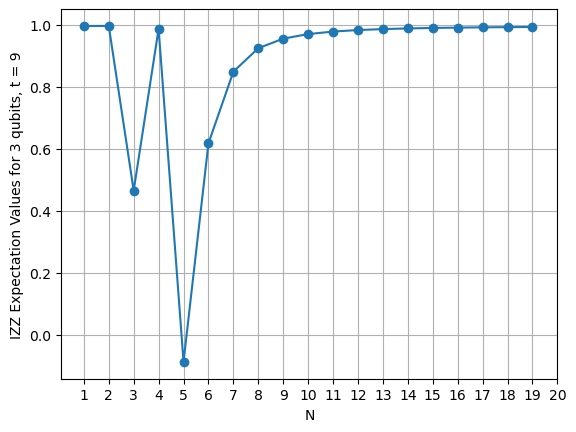

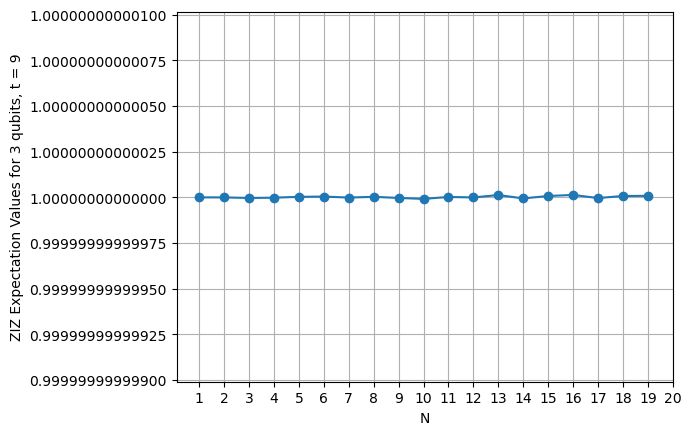

In [87]:
for i in np.arange(1.0, 10.0, 1.0):
    exp_val_one_observable(3, 20, 1, i) #ZZI
    exp_val_one_observable(3, 20, 2, i) #IZZ
    exp_val_one_observable(3, 20, 3, i) #ZIZ

<h1>T on the x-axis</h1>

In [115]:
def exp_val_one_observable_t_axis(n, N, o, t):
    exp_vals = []
    Ts = np.arange(1.0, t+1.0, 1.0)
    for i in Ts:
        exp_val = plot_measurement_loop_one_observable(n, N, o, i)[1][0]
        exp_vals.append(exp_val)

    plt.plot(Ts, exp_vals, "-o")
    plt.xticks(np.arange(1, int(t+1), 1))
    plt.ticklabel_format(useOffset=False, style='plain', axis='y')
    plt.xlabel("t")
    plt.ylabel(f"{observables_labels[o]} Expectation Values for {n} qubits, N = {N}")
    plt.title("")
    plt.grid(True)
    plt.show()

    # return statement can return the array of expectation values
    # return exp_vals

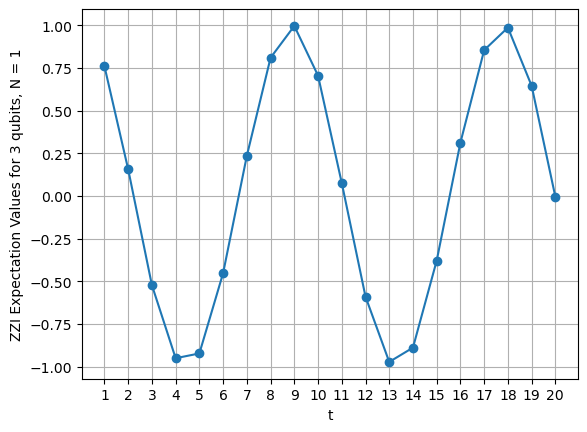

In [117]:
exp_val_one_observable_t_axis(3, 1, 1, 20.0)

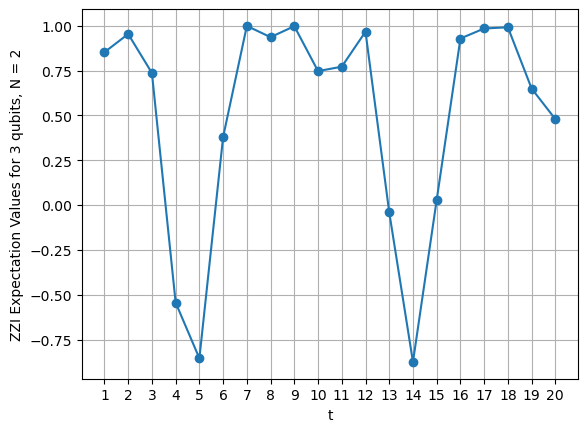

In [119]:
exp_val_one_observable_t_axis(3, 2, 1, 20.0)

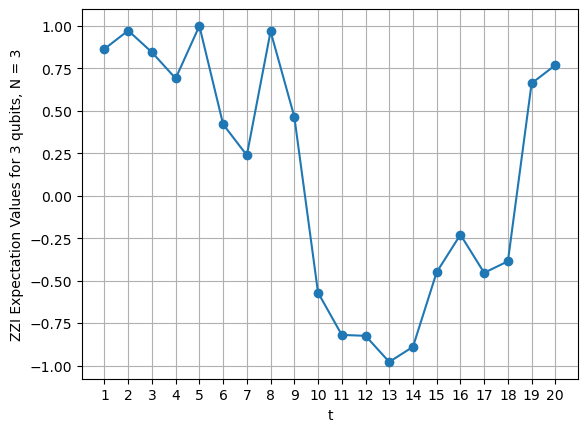

In [121]:
exp_val_one_observable_t_axis(3, 3, 1, 20.0)